![Banner](../../../../Images/Banner/03_spatial_analysis/03_07_banner_spatial_causal.png)

# Spatially Varying Treatment Effects



This notebook maps the county-level effect of the community-health-worker
program. The effect is larger where child poverty is high, and larger in the
Deep South. The data are Scenario A without spillovers (`y_noint`).

The estimators are a DR-learner, geographically weighted double machine
learning, and a geographically weighted causal forest. The classes are
`SpatialDRLearner` and `GWDML` in `geolattice.spatial_analysis.spatialcausal`.



## Table of Contents

- [Overview](#overview)
- [The conditional average treatment effect](#the-conditional-average-treatment-effect)
- [Geographically weighted DML](#geographically-weighted-dml)
- [The geographically weighted causal forest](#the-geographically-weighted-causal-forest)
- [Using CATEs: targeting a limited budget](#using-cates-targeting-a-limited-budget)
- [Summary and Conclusions](#summary-and-conclusions)
- [Resources](#resources)


## Overview

A single average effect hides *where* a program works. In Scenario A the true effect

$$\tau_i=-0.8-0.35\,z(\text{child poverty})_i-0.6\,\exp\!\Big(-\tfrac{\lVert s_i-s_{\text{Jackson,MS}}\rVert^2}{2\cdot400^2}\Big)$$

is larger in poorer counties and in the Deep South. We try to recover this surface, still in the
presence of the smooth confounder $U(s)$. We use the outcome without spillovers (`y_noint`)
because these estimators assume no interference.


**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import geolattice.spatial_analysis.spatialcausal as sc, countycausal as cc, tutorial_style as ts
ts.use()

gA, w, truth = cc.scenario_program()
X = gA[cc.COVARIATES].to_numpy()
xy = cc.coords_km(gA)
tau = gA["tau"].to_numpy()
data = sc.SpatialCausalData(X, gA["T"], gA["y_noint"], xy, w=w, feature_names=cc.COVARIATES)
print(f"true ATE {truth['ate']:.3f};  tau ranges from {tau.min():.2f} to {tau.max():.2f}")

true ATE -0.890;  tau ranges from -4.27 to -0.09


***
## The conditional average treatment effect

The CATE is $\tau(x,s)=\mathbb E[Y(1)-Y(0)\mid X=x,\,s]$. Under unconfoundedness given $(X,s)$
it is identified, but it is a *function*, estimated with much more noise than an average.

### The AIPW pseudo-outcome and the DR-learner

With cross-fitted nuisances $\hat\mu_t(x,s)=\mathbb E[Y\mid T=t,X,s]$ and $\hat e(x,s)$, define

$$\Gamma_i=\hat\mu_1(Z_i)-\hat\mu_0(Z_i)+\frac{T_i\,(Y_i-\hat\mu_1(Z_i))}{\hat e(Z_i)}-\frac{(1-T_i)\,(Y_i-\hat\mu_0(Z_i))}{1-\hat e(Z_i)} .$$

If either nuisance is correct, $\mathbb E[\Gamma_i\mid X_i,s_i]=\tau(X_i,s_i)$. So
$\frac1n\sum_i\Gamma_i$ is the doubly robust ATE, and regressing $\Gamma$ on effect modifiers gives
the **DR-learner** (Kennedy, 2023), whose error depends only on the *product* of the two nuisance
errors. The catch: $\Gamma$ is very noisy. Its variance is about that of $Y$ itself and more than
ten times the variance of the signal $\tau$, so the second stage needs strong smoothing. In `SpatialDRLearner` the nuisance models see covariates plus the spatial
basis (to absorb $U$), and the final stage regresses $\Gamma$ on covariates and coordinates.
All CATEs reported below are **out-of-fold**: a county's estimate never uses its own outcome.


In [2]:
dr = sc.SpatialDRLearner(spatial_features=("rbf",), cate_features="X+coords", se="conley", cutoff=150).fit(data)
print(dr.summary())
print(f"variance of the pseudo-outcome: {dr.pseudo_outcome_.var():.2f}   of Y: {gA['y_noint'].var():.2f}   "
      f"of the true effect tau: {tau.var():.2f}")

Spatial DR-learner  (n=3109, SE: conley)
        estimate     se  ci_lower  ci_upper  p_value
effect                                              
ate      -0.8286 0.0474   -0.9216   -0.7357   0.0000
  propensity_range: (0.025, 0.97)
variance of the pseudo-outcome: 4.38   of Y: 4.74   of the true effect tau: 0.19


***
## Geographically weighted DML

GW-DML keeps the global, spatially cross-fitted residuals of notebook 01,
$\hat u_j=Y_j-\hat\ell(Z_j)$ and $\hat v_j=T_j-\hat m(Z_j)$, and fits a *local* residual-on-residual
regression around each county. With kernel weights $K_{ij}=K(d_{ij}/h_i)$ the local estimating
equation is

$$\sum_j K_{ij}\,(\hat v_j-\bar v_i)\big(\hat u_j-\bar u_i-\theta_i(\hat v_j-\bar v_i)\big)=0
\;\Rightarrow\;
\hat\theta_i=\frac{\sum_jK_{ij}(\hat v_j-\bar v_i)(\hat u_j-\bar u_i)}{\sum_jK_{ij}(\hat v_j-\bar v_i)^2},$$

with kernel-weighted means $\bar u_i,\bar v_i$ (a local intercept). This is a geographically
weighted regression of $\hat u$ on $\hat v$.

* **Kernel and bandwidth** come from `geolattice.spatial_statistics.gwmodel`: bisquare
  $K(r)=(1-r^2)^2$ for $r<1$, and an adaptive bandwidth $h_i$ equal to the distance to the $k$-th
  nearest county. $k$ is chosen by golden-section search on the leave-one-out error
  $\sum_j\big(\hat u_j-\bar u_{(-j)}-\hat\theta_{(-j)}(\hat v_j-\bar v_{(-j)})\big)^2$.
* **Local standard error** (kernel sandwich, treating the residuals as independent):
  $\widehat{\operatorname{se}}(\hat\theta_i)=\sqrt{\sum_jK_{ij}^2(\hat v_j-\bar v_i)^2\hat e_{ij}^2}\big/\sum_jK_{ij}(\hat v_j-\bar v_i)^2$,
  and the effective sample size is $n_{\text{eff},i}=(\sum_jK_{ij})^2/\sum_jK_{ij}^2$.
* **What it estimates.** As with the global PLM, $\theta_i$ is a *local overlap-weighted* average of
  $\tau$ in the kernel neighbourhood, and smoothing biases it toward neighbouring values.
* **Stationarity test.** Is there spatial variation at all? The statistic is the SD of the
  $\hat\theta_i$. Under $H_0$ (constant effect) the residual pairs $(\hat u_j,\hat v_j)$ are
  exchangeable across locations, so permuting them gives the null distribution
  (cf. Brunsdon, Fotheringham & Charlton, 1998).


In [3]:
gw = sc.GWDML(model_y="ridge", model_t="logistic", spatial_features=("rbf",), kernel="bisquare", fixed=False).fit(data)
print(gw.summary())
print(gw.local_effects_[["theta", "se", "eff_n"]].describe().round(3))

GW-DML  (n=3109, SE: iid)
        estimate     se  ci_lower  ci_upper  p_value
effect                                              
ate      -0.8984 0.0262   -0.9498   -0.8471   0.0000
  kernel: bisquare (adaptive)
  bandwidth: 36.0
  local_theta_range: (-11.583, 1.156)
  share_local_significant: 0.877
          theta        se     eff_n
count  3109.000  3109.000  3109.000
mean     -0.915     0.240    20.566
std       0.559     0.244     1.533
min     -11.583     0.037    14.429
25%      -1.129     0.154    19.627
50%      -0.842     0.205    20.453
75%      -0.622     0.270    21.356
max       1.156     5.590    28.412


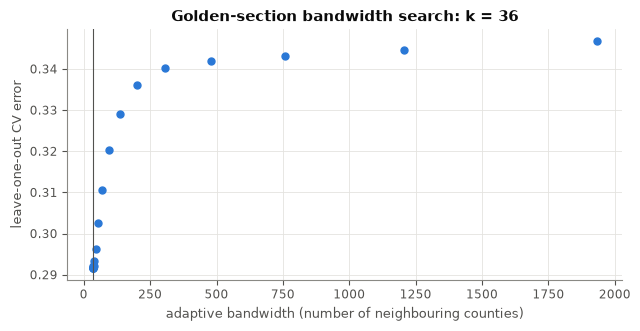

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
h = gw.bandwidth_history_.sort_values("bandwidth")
ax.plot(h.bandwidth, h.cv, "o", color=ts.BLUE, ms=5)
ax.axvline(gw.bandwidth_, color=ts.INK2, lw=0.8)
ax.set_xlabel("adaptive bandwidth (number of neighbouring counties)"); ax.set_ylabel("leave-one-out CV error")
ax.set_title(f"Golden-section bandwidth search: k = {gw.bandwidth_:.0f}")
plt.tight_layout()

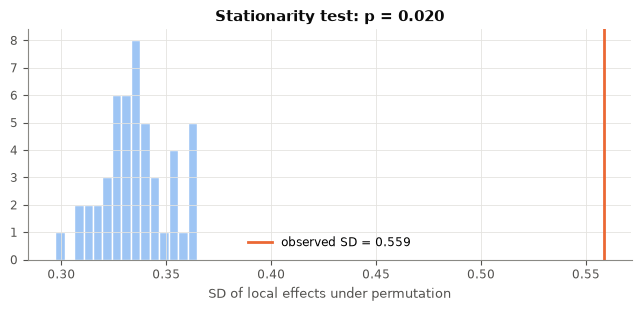

In [5]:
stat, pval, null = gw.stationarity_test(n_perm=49)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(null, bins=15, color="#9ec5f4", edgecolor="white")
ax.axvline(stat, color=ts.ORANGE, lw=2, label=f"observed SD = {stat:.3f}")
ax.set_xlabel("SD of local effects under permutation"); ax.set_title(f"Stationarity test: p = {pval:.3f}")
ax.legend(); plt.tight_layout()

***
## The geographically weighted causal forest

Local regression of $\hat u$ on $\hat v$ is linear and only uses location. The GW causal forest
lets the effect also vary with covariates, nonlinearly:

1. Compute cross-fitted AIPW pseudo-outcomes $\Gamma_i$ (as for the DR-learner).
2. Place $K=50$ calibration **knots** (k-means of county centroids). At knot $k$ fit a random forest
   of $\Gamma$ on covariates with sample weights $K(d_{jk}/h_k)$ (the same `geolattice.spatial_statistics` kernel).
3. Each county uses its nearest knot's forest, blended with a global forest:
   $\hat\tau_i=\lambda\,\hat\tau^{\text{local}}_i+(1-\lambda)\,\hat\tau^{\text{global}}_i$
   (the geographical random forest idea of Georganos et al., 2021).
4. All predictions are **out-of-bag**, and $\lambda$ and the leaf size are chosen by out-of-bag error
   (leaf size matters a great deal because $\Gamma$ is so noisy).

The bandwidth is chosen as the scale at which a kernel-weighted mean of $\Gamma$ best predicts
held-out values. That smoothed mean is itself reported as a **local ATE map** with a kernel
sandwich SE, $\hat\tau^{\text{loc}}_i=\sum_jK_{ij}\Gamma_j/\sum_jK_{ij}$. This step uses the
`geolattice.spatial_statistics.gwmodel` kernels; `engine="spatialstats"` would instead run
`geolattice.spatial_statistics.gwmodel.ensemble.GWRandomForest` with one local forest per county.


In [6]:
cf = sc.GWCausalForest(spatial_features=("rbf",), n_knots=50).fit(data)
print(cf.summary())

GW causal forest  (n=3109, SE: iid)
        estimate     se  ci_lower  ci_upper  p_value
effect                                              
ate      -0.8286 0.0375   -0.9022   -0.7551   0.0000
  engine: knots
  kernel: bisquare (adaptive)
  bandwidth: 194.0
  local_weight: 0.4
  min_samples_leaf: 58
  propensity_range: (0.025, 0.97)


In [7]:
def scores(est):
    return pd.Series({"corr with true tau": np.corrcoef(est, tau)[0, 1],
                      "RMSE": np.sqrt(np.mean((est - tau) ** 2)),
                      "mean": np.mean(est)})

comp = pd.DataFrame({"DR-learner (out-of-fold)": scores(dr.cate_),
                     "GW-DML local theta": scores(gw.local_effects_["theta"].to_numpy()),
                     "GW causal forest (out-of-bag)": scores(cf.cate_),
                     "GW local ATE map": scores(cf.local_ate_["ate"].to_numpy())}).T
comp["mean"] = comp["mean"].round(3)
print(f"true mean effect: {tau.mean():.3f}")
comp.round(3)

true mean effect: -0.890


,corr with true tau,RMSE,mean
DR-learner (out-of-fold),0.820,0.309,-0.830
GW-DML local theta,0.458,0.528,-0.915
GW causal forest (out-of-bag),0.888,0.207,-0.835
GW local ATE map,0.646,0.364,-0.839


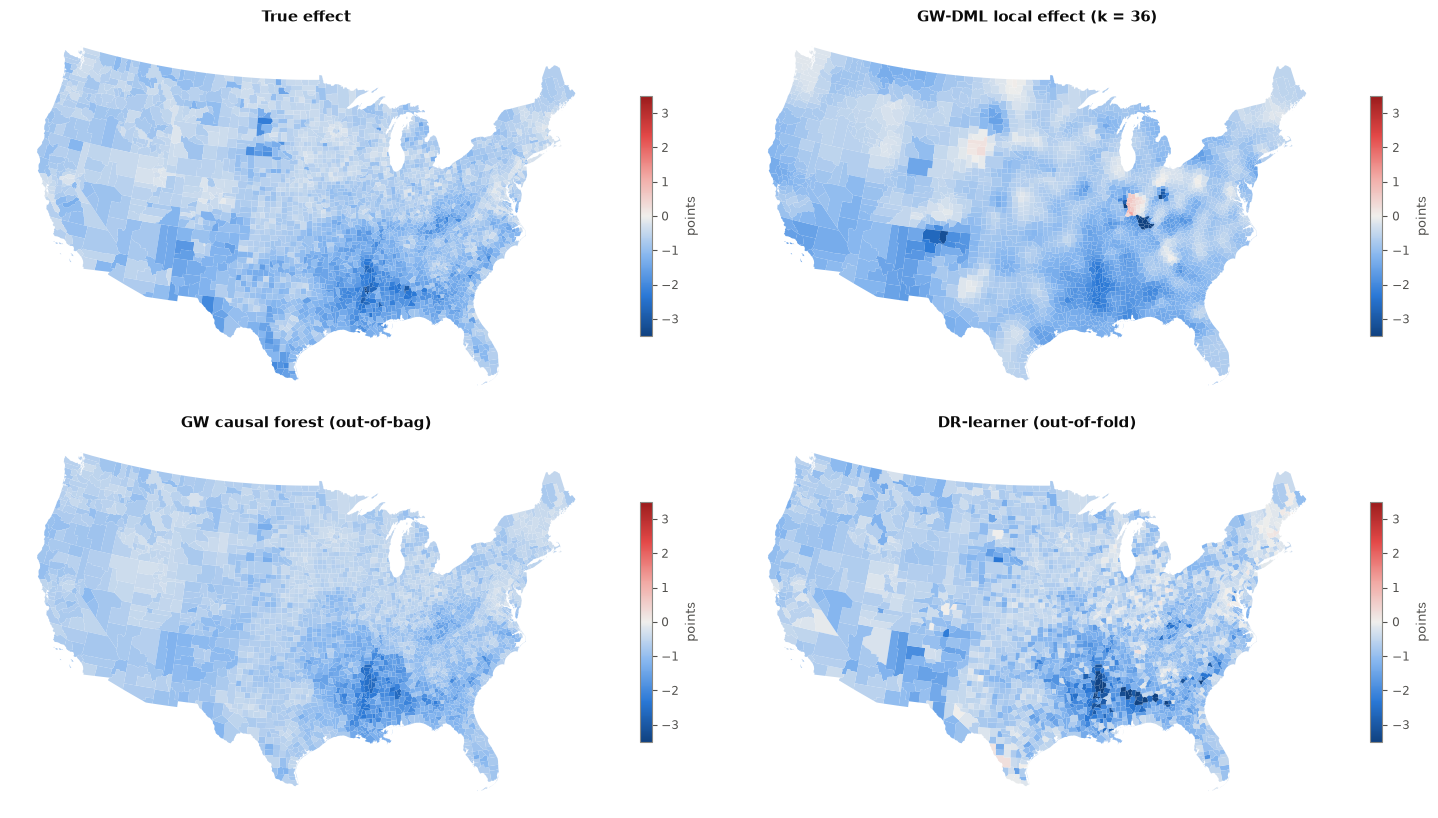

In [8]:
lim = dict(vmin=-3.5, vmax=3.5)
fig, ax = plt.subplots(2, 2, figsize=(15, 8.4))
ts.county_map(gA, tau, ax[0, 0], cmap=ts.DIV, center=0, title="True effect", label="points", **lim)
ts.county_map(gA, gw.local_effects_["theta"].to_numpy(), ax[0, 1], cmap=ts.DIV, center=0,
              title=f"GW-DML local effect (k = {gw.bandwidth_:.0f})", label="points", **lim)
ts.county_map(gA, cf.cate_, ax[1, 0], cmap=ts.DIV, center=0, title="GW causal forest (out-of-bag)", label="points", **lim)
ts.county_map(gA, dr.cate_, ax[1, 1], cmap=ts.DIV, center=0, title="DR-learner (out-of-fold)", label="points", **lim)
plt.tight_layout()

The forests recover both drivers of heterogeneity (poverty and the Deep-South bump). GW-DML
captures the regional pattern, but the CV-selected bandwidth is small (about 20 effective
counties per neighbourhood), so local estimates are noisy and a few with almost no local treatment
variation are extreme (the minimum is below −10, with a standard error above 5). It also cannot
express the within-region poverty gradient, because it uses location only. A larger bandwidth
trades this variance for more smoothing bias.

How do the estimates relate to the two true drivers? Averaging the CATE estimates within bins of
child poverty and of distance to Jackson, MS:


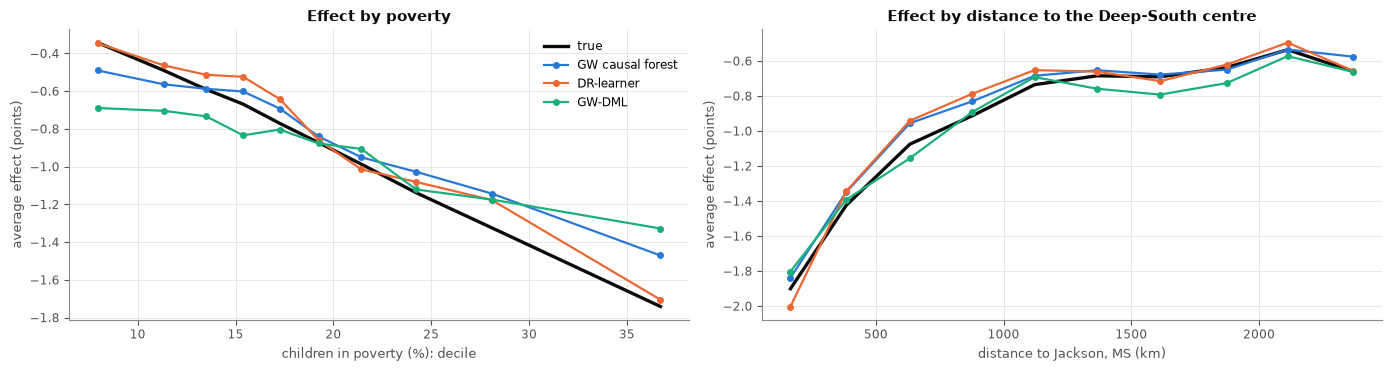

In [9]:
jack = xy[(gA.state_abbr == "MS").to_numpy() & (gA.county == "Hinds").to_numpy()][0]
dist = np.sqrt(((xy - jack) ** 2).sum(1))
df = pd.DataFrame({"poverty": gA.child_poverty_pct, "dist": dist, "true": tau, "GW causal forest": cf.cate_,
                   "DR-learner": dr.cate_, "GW-DML": gw.local_effects_["theta"].to_numpy()})
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for a, (col, bins, lab) in zip(ax, [("poverty", np.quantile(df.poverty, np.linspace(0, 1, 11)), "children in poverty (%): decile"),
                                     ("dist", np.linspace(0, 2500, 11), "distance to Jackson, MS (km)")]):
    g = df.groupby(pd.cut(df[col], bins, include_lowest=True), observed=True).mean(numeric_only=True)
    for name, color in [("true", ts.TRUTH), ("GW causal forest", ts.BLUE), ("DR-learner", ts.ORANGE), ("GW-DML", ts.AQUA)]:
        a.plot(g[col], g[name], "o-" if name != "true" else "-", color=color, label=name, ms=4,
               lw=2.4 if name == "true" else 1.6)
    a.set_xlabel(lab); a.set_ylabel("average effect (points)")
ax[0].legend(); ax[0].set_title("Effect by poverty"); ax[1].set_title("Effect by distance to the Deep-South centre")
plt.tight_layout()

***
## Using CATEs: targeting a limited budget

Suppose the budget covers 20% of counties. Ranking counties by estimated effect and treating the
top fifth targets those predicted to benefit most. We compare the *true* average effect in the
targeted counties with random allocation and with oracle targeting by the true $\tau$.


In [10]:
k = int(0.2 * len(tau))
def gain(est):
    pick = np.argsort(est)[:k]                    # most negative = largest reduction in diabetes
    return tau[pick].mean()
tgt = pd.Series({"random allocation": tau.mean(), "DR-learner": gain(dr.cate_), "GW-DML": gain(gw.local_effects_["theta"].to_numpy()),
                 "GW causal forest": gain(cf.cate_), "oracle (true tau)": gain(tau)},
                name="true mean effect in the 20% targeted counties")
tgt.round(3).to_frame()

,true mean effect in the 20% targeted counties
random allocation,-0.890
DR-learner,-1.462
GW-DML,-1.365
GW causal forest,-1.510
oracle (true tau),-1.572


***
## Summary and Conclusions

1. CATE estimation is much harder than ATE estimation: pseudo-outcomes are noisy, so methods
   need heavy smoothing, and honest (out-of-fold / out-of-bag) predictions are the only fair basis
   for comparison.
2. GW-DML answers "where?", with local SEs and a test of whether the effect varies at all. It
   cannot see covariate-driven heterogeneity, and pointwise intervals are not a joint band.
3. The GW causal forest combines location and covariates and recovers both drivers here.
4. Even imperfect CATEs can be useful for targeting. The relevant measure is the true benefit
   in the selected counties, not the accuracy of each county's estimate.


***
## Resources

### Papers

| Reference | Notes |
|-----------|-------|
| Kennedy (2023) | DR-learner: second-stage regression of the AIPW pseudo-outcome |
| Brunsdon, Fotheringham & Charlton (1998) | Geographically weighted regression; permutation test of stationarity |
| Georganos et al. (2021) | Geographical random forests: blend a local forest with a global one |

### In this library

| Object | Role |
|--------|------|
| `SpatialDRLearner` | Cross-fitted DR-learner with a spatial basis in the nuisance models |
| `GWDML` | Local residual-on-residual regression, bandwidth search, stationarity test |
| GW causal forest | Kernel-weighted forests of the pseudo-outcome at calibration knots |
